In [254]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error , r2_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout,Input



# 1. Load Data & Filter Country


In [255]:
df = pd.read_csv('/kaggle/input/datasets/patricklford/world-energy-consumption/World_Energy_By_Country_And_Region_1965_to_2023.csv')
print(df.columns)

Index(['Country', '1965', '1966', '1967', '1968', '1969', '1970', '1971',
       '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980',
       '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989',
       '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998',
       '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007',
       '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016',
       '2017', '2018', '2019', '2020', '2021', '2022', '2023'],
      dtype='object')


In [256]:
df = pd.read_csv('/kaggle/input/datasets/patricklford/world-energy-consumption/World_Energy_By_Country_And_Region_1965_to_2023.csv')

# 1. Filter for the US right from the start
country_df = df[df['Country'] == 'US'].copy()

# 2. Reshape the data so years become a column and values become consumption
country_df = country_df.melt(id_vars=['Country'], var_name='year', value_name='primary_energy_consumption')

# 3. Ensure year is treated as a number and sort it
country_df['year'] = country_df['year'].astype(int)
country_df = country_df.sort_values('year')

target_col = 'primary_energy_consumption'

In [257]:
# Convert the consumption column from strings to numbers
country_df['primary_energy_consumption'] = pd.to_numeric(country_df['primary_energy_consumption'], errors='coerce')

# Now calculate the year-over-year change
country_df['consumption_change'] = country_df['primary_energy_consumption'].diff()
country_df = country_df.dropna() # Remove the first row which will be NaN
target_col = 'consumption_change'

### 2. Chronological Train-Test Split (BEFORE SCALING to prevent leak)


In [258]:
raw_data = country_df[[target_col]].ffill().bfill().values


### Split data sequentially: 80% Train, 20% Test

In [259]:
train_size = int(len(raw_data) * 0.8)
train_raw = raw_data[:train_size]
test_raw = raw_data[train_size:]

### Scale using ONLY training data statistics (Prevents Data Leakage)

In [260]:
scaler = StandardScaler()
train_scaled = scaler.fit_transform(train_raw)
test_scaled = scaler.transform(test_raw)  # Transform test using train fit

### Combine scaled series for sequence creation (uses past test values sequentially)

In [261]:
full_scaled = np.vstack((train_scaled, test_scaled))

### 3. Create Sequences (5-Year Window)

In [262]:
def create_sequences(data, time_steps=5):
    X, y = [], []
    for i in range(len(data) - time_steps):
        X.append(data[i : i + time_steps])
        y.append(data[i + time_steps])
    return np.array(X), np.array(y)

LOOKBACK = 5

### Reconstruct train/test sequences strictly maintaining chronological bounds

In [263]:
X, y = create_sequences(full_scaled, time_steps=LOOKBACK)

# Split sequences at the matching index relative to training length
split_idx = train_size - LOOKBACK
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

### 4. Optimized LSTM Architecture

In [264]:
model = Sequential([
    Input(shape=(LOOKBACK, 1)),  # <-- Explicit Input layer goes here
    LSTM(16, activation='relu', return_sequences=False), # <-- Removed input_shape from here
    Dropout(0.1),
    Dense(1)
])

model.compile(optimizer='adam', loss='mean_squared_error')

# Train model (changed verbose=0 to verbose=2 so you can see it train!)
model.fit(X_train, y_train, epochs=400, batch_size=4, verbose=2)

Epoch 1/400
11/11 - 4s - 326ms/step - loss: 1.0145
Epoch 2/400
11/11 - 0s - 7ms/step - loss: 1.0242
Epoch 3/400
11/11 - 0s - 7ms/step - loss: 0.9999
Epoch 4/400
11/11 - 0s - 7ms/step - loss: 1.0122
Epoch 5/400
11/11 - 0s - 7ms/step - loss: 1.0396
Epoch 6/400
11/11 - 0s - 7ms/step - loss: 0.9994
Epoch 7/400
11/11 - 0s - 7ms/step - loss: 0.9993
Epoch 8/400
11/11 - 0s - 7ms/step - loss: 0.9816
Epoch 9/400
11/11 - 0s - 7ms/step - loss: 1.0068
Epoch 10/400
11/11 - 0s - 7ms/step - loss: 0.9777
Epoch 11/400
11/11 - 0s - 7ms/step - loss: 0.9883
Epoch 12/400
11/11 - 0s - 8ms/step - loss: 0.9976
Epoch 13/400
11/11 - 0s - 8ms/step - loss: 0.9974
Epoch 14/400
11/11 - 0s - 8ms/step - loss: 1.0017
Epoch 15/400
11/11 - 0s - 7ms/step - loss: 0.9702
Epoch 16/400
11/11 - 0s - 7ms/step - loss: 1.0181
Epoch 17/400
11/11 - 0s - 7ms/step - loss: 0.9841
Epoch 18/400
11/11 - 0s - 7ms/step - loss: 0.9962
Epoch 19/400
11/11 - 0s - 7ms/step - loss: 0.9915
Epoch 20/400
11/11 - 0s - 7ms/step - loss: 0.9810
Epoch 2

### 5. Predictions & Evaluation

In [265]:
predictions_scaled = model.predict(X_test)

# Rescale back to original values
predictions = scaler.inverse_transform(predictions_scaled)
y_test_actual = scaler.inverse_transform(y_test)

mae = mean_absolute_error(y_test_actual, predictions)
rmse = np.sqrt(mean_squared_error(y_test_actual, predictions))
# Calculate R-squared
r2 = r2_score(y_test_actual, predictions)

# Calculate MAPE
mape = np.mean(np.abs((y_test_actual - predictions) / y_test_actual)) * 100
print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R-square: {r2:.4f}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 382ms/step
MAE:  2.48
RMSE: 3.25
R-square: -0.2265


# 6. Plotting Results

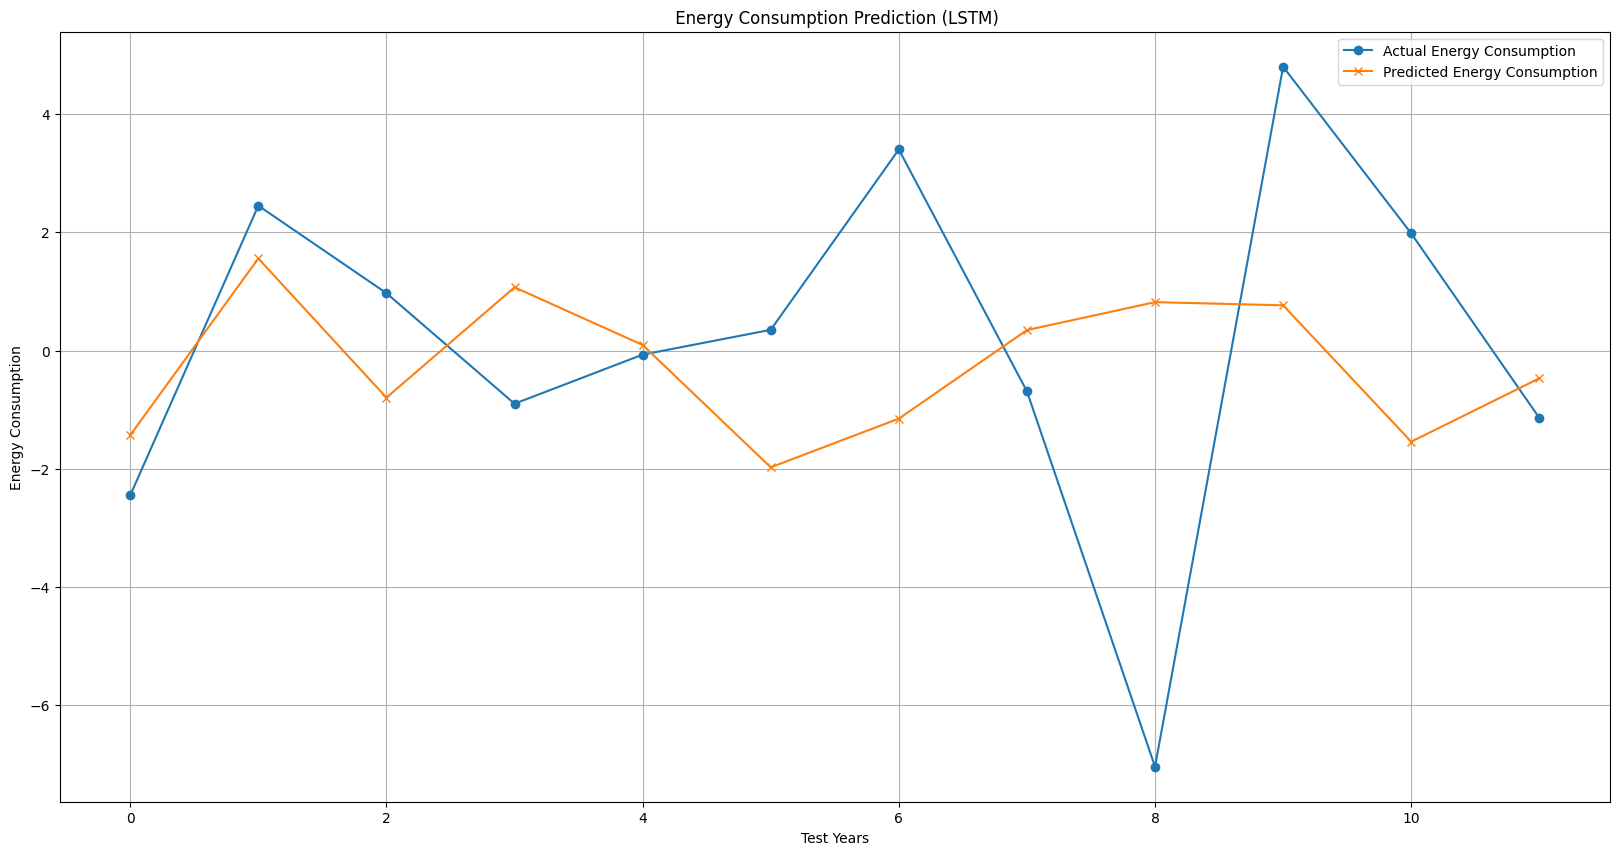

In [266]:
plt.figure(figsize=(20, 10))
plt.plot(y_test_actual, label='Actual Energy Consumption', marker='o')
plt.plot(predictions, label='Predicted Energy Consumption', marker='x')
plt.title(' Energy Consumption Prediction (LSTM)')
plt.xlabel('Test Years')
plt.ylabel('Energy Consumption')
plt.legend()
plt.grid(True)
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 435ms/step
Optimal Epochs Trained: 50
MAE:  2.19
RMSE: 2.97
R-square: -0.0228


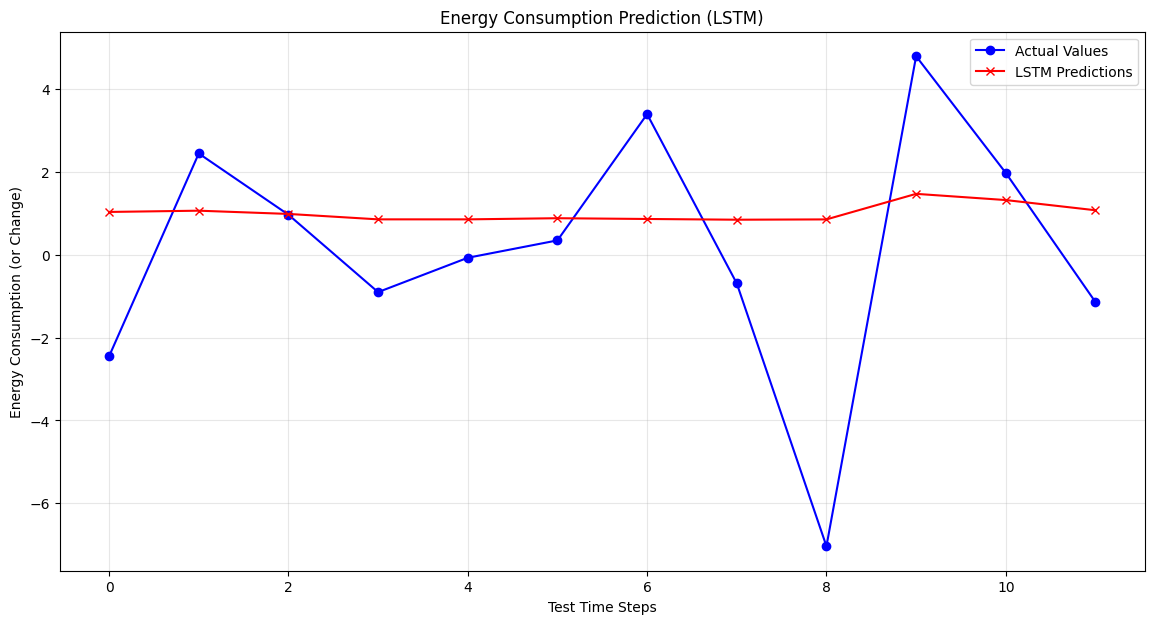

In [267]:
from tensorflow.keras.callbacks import EarlyStopping

# 1. Cleaned Up Scaling (Run once!)
scaler = StandardScaler()
train_scaled = scaler.fit_transform(train_raw)
test_scaled = scaler.transform(test_raw) 

full_scaled = np.vstack((train_scaled, test_scaled))

# 2. Sequence Creation
def create_sequences(data, time_steps=3): # Reduced lookback
    X, y = [], []
    for i in range(len(data) - time_steps):
        X.append(data[i : i + time_steps])
        y.append(data[i + time_steps])
    return np.array(X), np.array(y)

LOOKBACK = 3 # Shorter lookback is better for tiny datasets
X, y = create_sequences(full_scaled, time_steps=LOOKBACK)

# Split sequences
split_idx = len(train_raw) - LOOKBACK
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

# 3. Optimized "Micro" LSTM Architecture
model = Sequential([
    Input(shape=(LOOKBACK, 1)),
    LSTM(8, activation='relu', return_sequences=False), # Halved the complexity
    Dropout(0.2), # Increased dropout to prevent memorization
    Dense(1)
])

model.compile(optimizer='adam', loss='mean_squared_error')

# 4. Early Stopping (Crucial for small data)
# This monitors the test set and stops training before it overfits
early_stop = EarlyStopping(monitor='val_loss', patience=30, restore_best_weights=True)

# Train model using validation data to trigger early stopping
history = model.fit(
    X_train, y_train, 
    validation_data=(X_test, y_test), 
    epochs=400, 
    batch_size=4, 
    verbose=0, # Set to 0 to keep output clean, the callbacks handle the rest
    callbacks=[early_stop]
)

# 5. Predictions & Re-scaling
predictions_scaled = model.predict(X_test)

predictions = scaler.inverse_transform(predictions_scaled)
y_test_actual = scaler.inverse_transform(y_test)

# 6. Evaluation
mae = mean_absolute_error(y_test_actual, predictions)
rmse = np.sqrt(mean_squared_error(y_test_actual, predictions))
r2 = r2_score(y_test_actual, predictions)

# Avoid division by zero in MAPE if any actual value is exactly 0
with np.errstate(divide='ignore', invalid='ignore'):
    mape = np.mean(np.abs((y_test_actual - predictions) / y_test_actual)) * 100

print(f"Optimal Epochs Trained: {len(history.history['loss'])}")
print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R-square: {r2:.4f}")

# 7. Plotting
plt.figure(figsize=(14, 7)) # Adjusted for standard screens
plt.plot(y_test_actual, label='Actual Values', marker='o', color='blue')
plt.plot(predictions, label='LSTM Predictions', marker='x', color='red')
plt.title('Energy Consumption Prediction (LSTM)')
plt.xlabel('Test Time Steps')
plt.ylabel('Energy Consumption (or Change)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

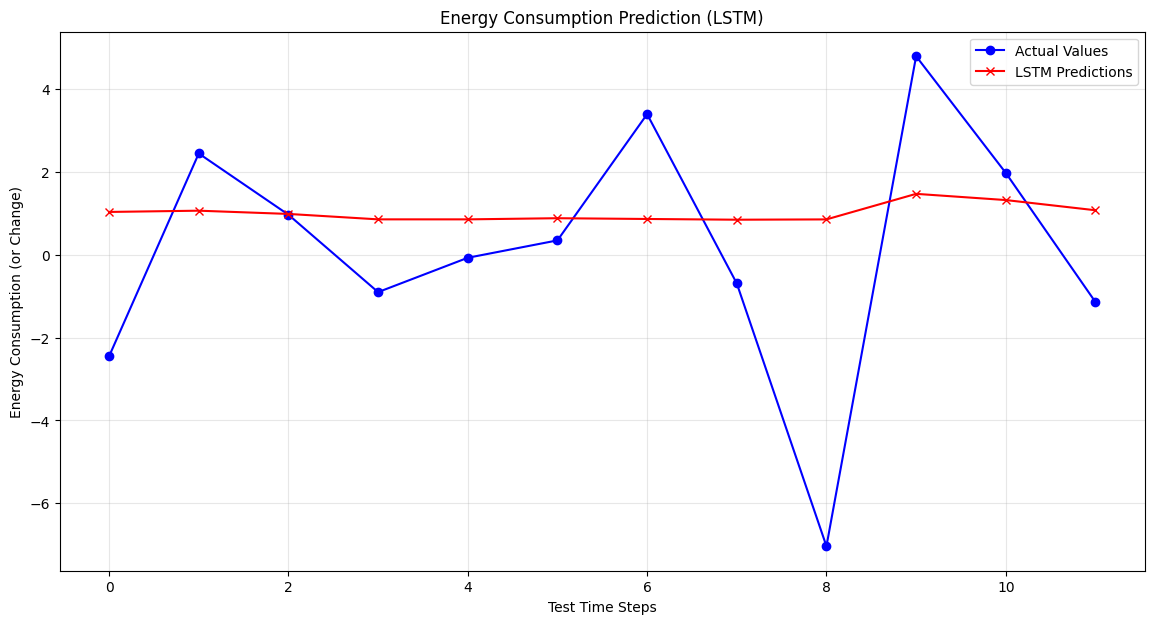

In [268]:
# 7. Plotting & Saving the Image
plt.figure(figsize=(14, 7))
plt.plot(y_test_actual, label='Actual Values', marker='o', color='blue')
plt.plot(predictions, label='LSTM Predictions', marker='x', color='red')
plt.title('Energy Consumption Prediction (LSTM)')
plt.xlabel('Test Time Steps')
plt.ylabel('Energy Consumption (or Change)')
plt.legend()
plt.grid(True, alpha=0.3)

# Save the plot locally as an image file
plt.savefig('energy_prediction_plot.png', dpi=300, bbox_inches='tight')
plt.show()

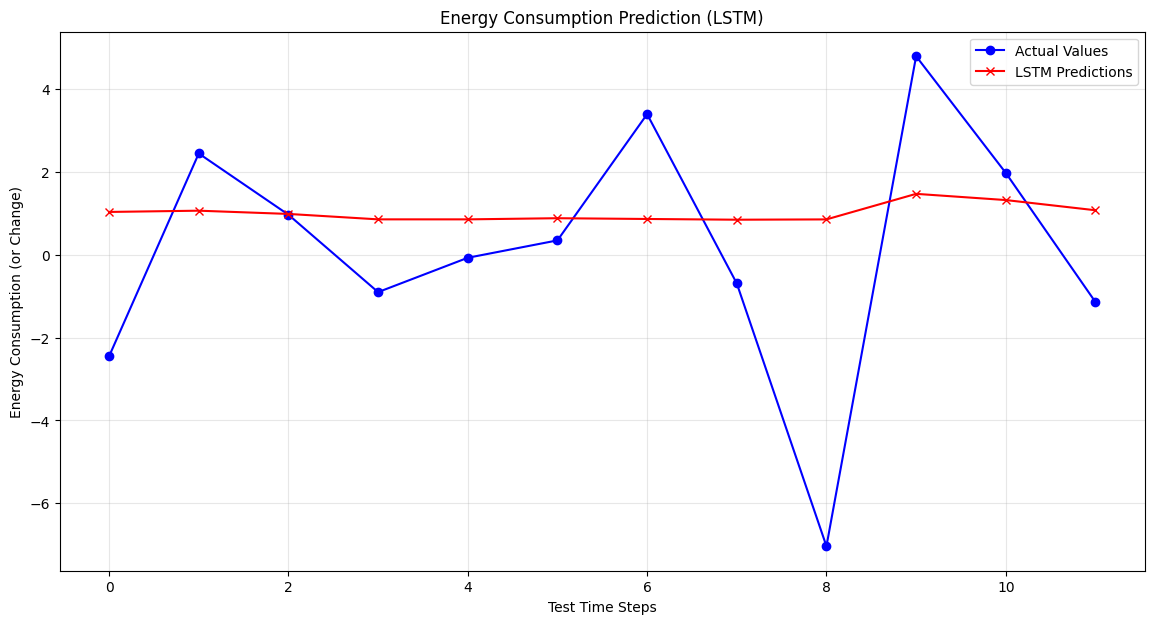

In [269]:
# 7. Plotting & Saving the Image
plt.figure(figsize=(14, 7))
plt.plot(y_test_actual, label='Actual Values', marker='o', color='blue')
plt.plot(predictions, label='LSTM Predictions', marker='x', color='red')
plt.title('Energy Consumption Prediction (LSTM)')
plt.xlabel('Test Time Steps')
plt.ylabel('Energy Consumption (or Change)')
plt.legend()
plt.grid(True, alpha=0.3)

# Save the plot locally as an image file
plt.savefig('energy_prediction_plot.png', dpi=300, bbox_inches='tight')
plt.show()